In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import datetime

In [2]:
df = pd.read_csv("../data/raw/T_ONTIME_REPORTING.csv")

In [3]:
df.head()

,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,...,DEST_STATE_ABR,DEST_STATE_NM,CRS_DEP_TIME,DEP_DEL15,DEP_TIME_BLK,CRS_ARR_TIME,CRS_ELAPSED_TIME,FLIGHTS,DISTANCE,DISTANCE_GROUP
0,1,3,5/1/2024 12:00:00 AM,9E,N131EV,4934,13487,1348702,31650,MSP,...,WI,Wisconsin,1950,0.0,1900-1959,2050,60.0,1.0,175.0,1
1,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5047,13487,1348702,31650,MSP,...,PA,Pennsylvania,1245,0.0,1200-1259,1552,127.0,1.0,726.0,3
2,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5047,14122,1412202,30198,PIT,...,MN,Minnesota,1632,0.0,1600-1659,1755,143.0,1.0,726.0,3
3,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5130,11193,1119302,33105,CVG,...,MN,Minnesota,1040,0.0,1000-1059,1142,122.0,1.0,596.0,3
4,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5167,11433,1143302,31295,DTW,...,KY,Kentucky,840,0.0,0800-0859,952,72.0,1.0,229.0,1


In [5]:
print(df["DEP_DEL15"].unique())

[ 0.  1. nan]


In [6]:
# Tipos de datos  por columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 609743 entries, 0 to 609742
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   DAY_OF_MONTH           609743 non-null  int64  
 1   DAY_OF_WEEK            609743 non-null  int64  
 2   FL_DATE                609743 non-null  str    
 3   OP_UNIQUE_CARRIER      609743 non-null  str    
 4   TAIL_NUM               608342 non-null  str    
 5   OP_CARRIER_FL_NUM      609743 non-null  int64  
 6   ORIGIN_AIRPORT_ID      609743 non-null  int64  
 7   ORIGIN_AIRPORT_SEQ_ID  609743 non-null  int64  
 8   ORIGIN_CITY_MARKET_ID  609743 non-null  int64  
 9   ORIGIN                 609743 non-null  str    
 10  ORIGIN_CITY_NAME       609743 non-null  str    
 11  ORIGIN_STATE_ABR       609743 non-null  str    
 12  DEST_AIRPORT_ID        609743 non-null  int64  
 13  DEST_AIRPORT_SEQ_ID    609743 non-null  int64  
 14  DEST_CITY_MARKET_ID    609743 non-null  int64  

In [7]:
# Shape y memoria -> HAY 609.743 Vuelos en el mes de mayo del 2024
print("Shape:", df.shape)

Shape: (609743, 27)


In [8]:
# 1. Chequeamos si hay registros nulos en la variable objetivo )dep_del15).
# Eso es un indicador si el vuelo esta cancelado o no
nulos_target = df['DEP_DEL15'].isna().sum()
print(f"Valores nulos en DEP_DEL15: {nulos_target}")

Valores nulos en DEP_DEL15: 7976


In [ ]:
# 2. Chequeamos los valores válidos presentes. .value cuenta la frecuencia de cada valor único en esa columna
print(df['DEP_DEL15'].value_counts(dropna=False))

DEP_DEL15
0.0    447354
1.0    154413
NaN      7976
Name: count, dtype: int64


In [3]:
# Filtramos los nulos de DEP_DEL15 (cancelaciones / no reportados)
df_validos = df.dropna(subset=['DEP_DEL15']).copy()
df_validos['DEP_DEL15'] = df_validos['DEP_DEL15'].astype(int)

print(f"Observaciones antes del filtrado: {len(df):,}")
print(f"Observaciones del universo válido: {len(df_validos):,}")

Observaciones antes del filtrado: 609,743
Observaciones del universo válido: 601,767


In [4]:
#Definición de variables redundantes a eliminar

cols_redundantes = [
    # Varianza cero
    'FLIGHTS',
    # Redundancias en Origen
    'ORIGIN_AIRPORT_ID',
    'ORIGIN_AIRPORT_SEQ_ID',
    'ORIGIN_CITY_NAME',
    # Redundancias en Destino 
    'DEST_AIRPORT_ID',
    'DEST_AIRPORT_SEQ_ID',
    'DEST_CITY_NAME',
    'DEST_STATE_NM',  
]

In [5]:
# Eliminación de variables redundantes
df_processed = df_validos.drop(columns=cols_redundantes)
print(
    f"Se eliminaron {len(cols_redundantes)} columnas redundantes con éxito.\n"
)

Se eliminaron 8 columnas redundantes con éxito.



In [6]:
df_processed.head()

,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_STATE_ABR,DEST_CITY_MARKET_ID,DEST,DEST_STATE_ABR,CRS_DEP_TIME,DEP_DEL15,DEP_TIME_BLK,CRS_ARR_TIME,CRS_ELAPSED_TIME,DISTANCE,DISTANCE_GROUP
0,1,3,5/1/2024 12:00:00 AM,9E,N131EV,4934,31650,MSP,MN,30424,CWA,WI,1950,0,1900-1959,2050,60.0,175.0,1
1,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5047,31650,MSP,MN,30198,PIT,PA,1245,0,1200-1259,1552,127.0,726.0,3
2,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5047,30198,PIT,PA,31650,MSP,MN,1632,0,1600-1659,1755,143.0,726.0,3
3,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5130,33105,CVG,KY,31650,MSP,MN,1040,0,1000-1059,1142,122.0,596.0,3
4,1,3,5/1/2024 12:00:00 AM,9E,N131EV,5167,31295,DTW,MI,33105,CVG,KY,840,0,0800-0859,952,72.0,229.0,1


In [7]:
#Casteo de datos
# Asegurar que los IDs de mercado y números de vuelo no se lean como valores numéricos
df_processed['ORIGIN_CITY_MARKET_ID'] = df_processed[
    'ORIGIN_CITY_MARKET_ID'
].astype(str)
df_processed['DEST_CITY_MARKET_ID'] = df_processed[
    'DEST_CITY_MARKET_ID'
].astype(str)

if 'OP_CARRIER_FL_NUM' in df_processed.columns:
  df_processed['OP_CARRIER_FL_NUM'] = df_processed[
      'OP_CARRIER_FL_NUM'
  ].astype(str)

print(f"Dimensiones finales procesadas: {df_processed.shape}")


Dimensiones finales procesadas: (601767, 19)


In [8]:
df_processed.info()
#Con esto, ya tenemos un dataset limpio y listo para el análisis exploratorio de datos (EDA) y la modelización. 
#DEBEMOS CHEQUEAR/MEJORAR para responder mejor la consigna de {" Identificación de la unidad de observación y de las variables"}

<class 'pandas.DataFrame'>
Index: 601767 entries, 0 to 609742
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   DAY_OF_MONTH           601767 non-null  int64  
 1   DAY_OF_WEEK            601767 non-null  int64  
 2   FL_DATE                601767 non-null  str    
 3   OP_UNIQUE_CARRIER      601767 non-null  str    
 4   TAIL_NUM               601767 non-null  str    
 5   OP_CARRIER_FL_NUM      601767 non-null  str    
 6   ORIGIN_CITY_MARKET_ID  601767 non-null  str    
 7   ORIGIN                 601767 non-null  str    
 8   ORIGIN_STATE_ABR       601767 non-null  str    
 9   DEST_CITY_MARKET_ID    601767 non-null  str    
 10  DEST                   601767 non-null  str    
 11  DEST_STATE_ABR         601767 non-null  str    
 12  CRS_DEP_TIME           601767 non-null  int64  
 13  DEP_DEL15              601767 non-null  int64  
 14  DEP_TIME_BLK           601767 non-null  str    
 15 

In [ ]:
#Es necesario analizar como manejar las variables de tiempo que están en formato HHMM,
# para que sean más fáciles de interpretar y potenciar el resultado de los arboles
df_processed[['CRS_DEP_TIME', 'CRS_ARR_TIME','CRS_ELAPSED_TIME' ]]


,CRS_DEP_TIME,CRS_ARR_TIME,CRS_ELAPSED_TIME
0,1950,2050,60.0
1,1245,1552,127.0
2,1632,1755,143.0
3,1040,1142,122.0
4,840,952,72.0
...,...,...,...
609738,700,859,119.0
609739,1457,1605,68.0
609740,1257,1408,71.0
609741,950,1213,143.0


In [10]:
# 1. Extraemos la hora programada (0 a 23) diviendo por 100 (la hora está en formato HHMM)
df_processed['CRS_DEP_HOUR'] = df_processed['CRS_DEP_TIME'] // 100
df_processed['CRS_ARR_HOUR'] = df_processed['CRS_ARR_TIME'] // 100

In [14]:
df_processed[['CRS_DEP_TIME', 'CRS_DEP_HOUR', 'CRS_ARR_TIME', 'CRS_ARR_HOUR']].head()


,CRS_DEP_TIME,CRS_DEP_HOUR,CRS_ARR_TIME,CRS_ARR_HOUR
0,1950,19,2050,20
1,1245,12,1552,15
2,1632,16,1755,17
3,1040,10,1142,11
4,840,8,952,9


In [15]:
# 2. Definimos nuevas franjas horarias operativas para la salida y facilitar el análisis de la variable objetivo.
# Intervalos: [0, 5], [6, 11], [12, 17], [18, 23]
bins = [-1, 5, 11, 17, 23]
labels = ['Madrugada', 'Mañana', 'Tarde', 'Noche']

df_processed['DEP_TIME_OF_DAY'] = pd.cut(
    df_processed['CRS_DEP_HOUR'], 
    bins=bins, 
    labels=labels
)

In [16]:
# 1. Verificar rangos de las nuevas columnas numéricas
print("Rangos de horas extraídas:")
print(df_processed[['CRS_DEP_HOUR', 'CRS_ARR_HOUR']].describe().T[['min', 'max', 'mean']])

# 2. Verificar distribución de vuelos por franja horaria
print("\nDistribución de vuelos por franja horaria:")
print(df_processed['DEP_TIME_OF_DAY'].value_counts(dropna=False))

Rangos de horas extraídas:
              min   max       mean
CRS_DEP_HOUR  0.0  23.0  13.032528
CRS_ARR_HOUR  0.0  23.0  14.631296

Distribución de vuelos por franja horaria:
DEP_TIME_OF_DAY
Mañana       233002
Tarde        212265
Noche        138389
Madrugada     18111
Name: count, dtype: int64


In [17]:
# 1. Agrupamos los datos por hora programada de salida (0 a 23 horas)
# Se calcula el volumen de vuelos y el porcentaje de retrasos para cada hora
hourly_delays = df_processed.groupby('CRS_DEP_HOUR')['DEP_DEL15'].agg(
    total_vuelos='count',  # Cantidad total de vuelos programados en esa hora
    tasa_demora='mean'     # Proporción de vuelos retrasados
)

print("Tasa de demora por hora programada (CRS_DEP_HOUR):")
print(hourly_delays)


Tasa de demora por hora programada (CRS_DEP_HOUR):
              total_vuelos  tasa_demora
CRS_DEP_HOUR                           
0                     1155     0.301299
1                      386     0.248705
2                      139     0.251799
3                       78     0.166667
4                       52     0.134615
5                    16301     0.086989
6                    42376     0.086110
7                    42158     0.109991
8                    41108     0.138002
9                    32740     0.163897
10                   38590     0.199274
11                   36030     0.219400
12                   36177     0.249274
13                   36103     0.268842
14                   32861     0.303643
15                   35198     0.318541
16                   34038     0.347053
17                   37888     0.349240
18                   36800     0.370734
19                   34651     0.393235
20                   26550     0.407194
21                   20804   

In [ ]:
# 2. Tasa de demora según la franja horaria operativa. Misma lógica que la anterior, ç
# pero agrupando por la nueva variable categórica DEP_TIME_OF_DAY
time_of_day_delays = df_processed.groupby('DEP_TIME_OF_DAY', observed=True)['DEP_DEL15'].agg(
    total_vuelos='count',
    tasa_demora='mean'
)
print("\nTasa de demora por franja horaria (DEP_TIME_OF_DAY):")
print(time_of_day_delays)


Tasa de demora por franja horaria (DEP_TIME_OF_DAY):
                 total_vuelos  tasa_demora
DEP_TIME_OF_DAY                           
Madrugada               18111     0.105847
Mañana                 233002     0.149870
Tarde                  212265     0.306028
Noche                  138389     0.380211


C:\Users\vagui\AppData\Local\Temp\ipykernel_10956\1527727248.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


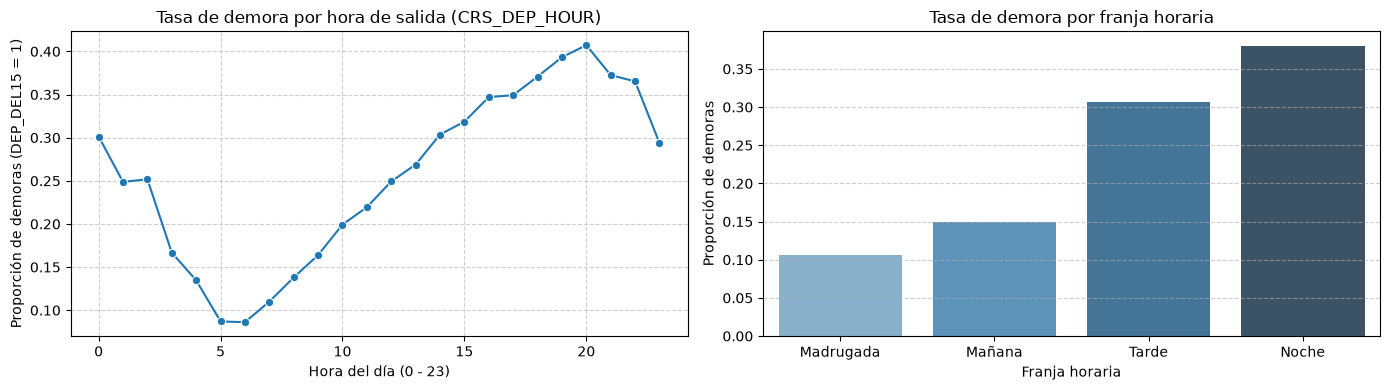

In [19]:
#Visualización grafica de los indicadores obtenidos. 
fig, axes = plt.subplots(1, 2, figsize=(14, 4)) #este comando prepara el terreno para  poner dos gráficos distintos, uno al lado del otro

# Gráfico 1: Tasa por hora entera
sns.lineplot(
    data=hourly_delays.reset_index(), 
    x='CRS_DEP_HOUR', 
    y='tasa_demora', 
    marker='o', 
    ax=axes[0]
)
axes[0].set_title('Tasa de demora por hora de salida (CRS_DEP_HOUR)')
axes[0].set_xlabel('Hora del día (0 - 23)')
axes[0].set_ylabel('Proporción de demoras (DEP_DEL15 = 1)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Gráfico 2: Tasa por franja operativa
sns.barplot(
    data=time_of_day_delays.reset_index(), 
    x='DEP_TIME_OF_DAY', 
    y='tasa_demora', 
    palette='Blues_d', 
    ax=axes[1]
)
axes[1].set_title('Tasa de demora por franja horaria')
axes[1].set_xlabel('Franja horaria')
axes[1].set_ylabel('Proporción de demoras')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [24]:
# Visto que fue exitoso la creacion de la variable categórica DEP_TIME_OF_DAY y la transformación de CRS_DEP_TIME y CRS_ARR_TIME
# a nuevas variables, podemos eliminar las variable originales  para simplificar el dataset.

df_processed = df_processed.drop(columns=['CRS_DEP_TIME', 'CRS_ARR_TIME'])


In [25]:
df_processed.info()

<class 'pandas.DataFrame'>
Index: 601767 entries, 0 to 609742
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   DAY_OF_MONTH           601767 non-null  int64   
 1   DAY_OF_WEEK            601767 non-null  int64   
 2   FL_DATE                601767 non-null  str     
 3   OP_UNIQUE_CARRIER      601767 non-null  str     
 4   TAIL_NUM               601767 non-null  str     
 5   OP_CARRIER_FL_NUM      601767 non-null  str     
 6   ORIGIN_CITY_MARKET_ID  601767 non-null  str     
 7   ORIGIN                 601767 non-null  str     
 8   ORIGIN_STATE_ABR       601767 non-null  str     
 9   DEST_CITY_MARKET_ID    601767 non-null  str     
 10  DEST                   601767 non-null  str     
 11  DEST_STATE_ABR         601767 non-null  str     
 12  DEP_DEL15              601767 non-null  int64   
 13  DEP_TIME_BLK           601767 non-null  str     
 14  CRS_ELAPSED_TIME       601767 non-nu

--- AUDITORÍA DE TASAS DIARIAS (DAY_OF_MONTH) ---
       total_vuelos  tasa_demora
count       31.0000      31.0000
mean     19411.8387       0.2555
std       1042.3215       0.0446
min      17216.0000       0.1442
25%      18949.0000       0.2289
50%      19872.0000       0.2533
75%      20259.5000       0.2823
max      20572.0000       0.3466


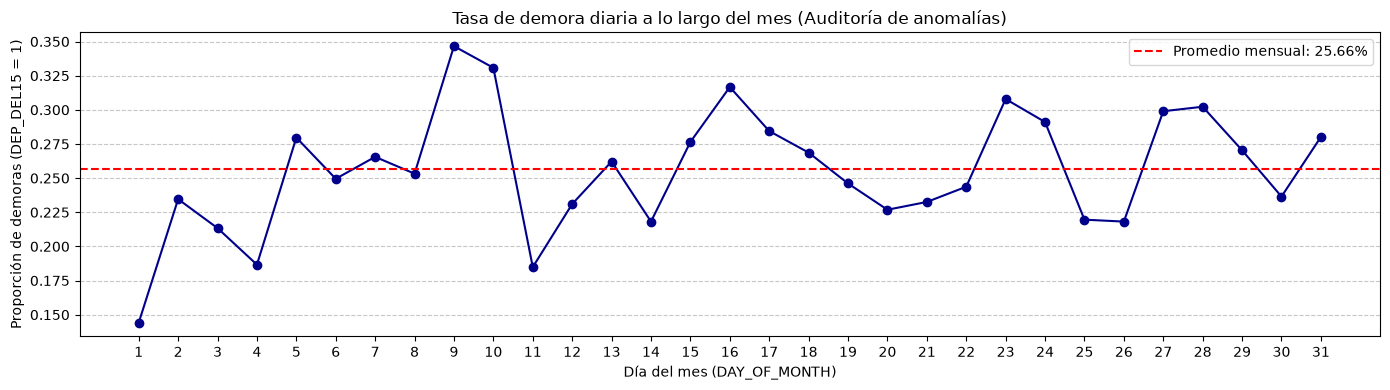

In [27]:
# DAY_OF_MONTH, al tratarse solamente de mayo, no generaliza como un ciclo mensual general, 
# y esta atada a eventos específicos de ese mes particular, con el riesgo de generar un sobre ajuste en el modelo.
# Sin embargo, es util para detectar días atípicos y evaluar su concecuencia en la demora o no de los vuelos.

daily_delay = df_processed.groupby('DAY_OF_MONTH')['DEP_DEL15'].agg(
    total_vuelos='count',
    tasa_demora='mean'
)

print("--- AUDITORÍA DE TASAS DIARIAS (DAY_OF_MONTH) ---")
print(daily_delay.describe().round(4))

# Visualización temporal del comportamiento mensual
plt.figure(figsize=(14, 4))
plt.plot(daily_delay.index, daily_delay['tasa_demora'], marker='o', color='darkblue', linewidth=1.5)
plt.axhline(df_processed['DEP_DEL15'].mean(), color='red', linestyle='--', label=f'Promedio mensual: {df_processed["DEP_DEL15"].mean():.2%}')
plt.title('Tasa de demora diaria a lo largo del mes (Auditoría de anomalías)')
plt.xlabel('Día del mes (DAY_OF_MONTH)')
plt.ylabel('Proporción de demoras (DEP_DEL15 = 1)')
plt.xticks(range(1, daily_delay.index.max() + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ONE-HOT ENCODING DE DAY_OF_WEEK. En base al estándar BTS: 1 = Lunes (Monday) a 7 = Domingo (Sunday)
dias_map = {
    1: 'Lunes', 
    2: 'Martes', 
    3: 'Miercoles', 
    4: 'Jueves', 
    5: 'Viernes', 
    6: 'Sabado', 
    7: 'Domingo'
}
df_processed['DAY_OF_WEEK_NAME'] = df_processed['DAY_OF_WEEK'].map(dias_map)

# Tasa empírica por día de la semana
weekday_delays = df_processed.groupby('DAY_OF_WEEK_NAME', observed=False)['DEP_DEL15'].agg(
    total_vuelos='count',
    tasa_demora='mean'
).reindex(dias_map.values())

print("\n--- TASA DE DEMORA POR DÍA DE LA SEMANA ---")
print(weekday_delays)

# One-Hot Encoding: Generar columnas dummy binarias (0 / 1)
# Se usa prefijo 'DOW' para trazabilidad limpia
df_dow_dummies = pd.get_dummies(
    df_processed['DAY_OF_WEEK_NAME'], 
    prefix='DOW', 
    dtype=int
)

# Incorporar las dummies al DataFrame
df_processed = pd.concat([df_processed, df_dow_dummies], axis=1)

print("\nColumnas generadas mediante One-Hot Encoding:")
print([col for col in df_processed.columns if col.startswith('DOW_')])


--- TASA DE DEMORA POR DÍA DE LA SEMANA ---
                  total_vuelos  tasa_demora
DAY_OF_WEEK_NAME                           
Lunes                    81110     0.259290
Martes                   75405     0.254201
Miercoles                95306     0.237614
Jueves                  100626     0.288663
Viernes                 101754     0.280018
Sabado                   69239     0.215096
Domingo                  78327     0.244296

Columnas generadas mediante One-Hot Encoding:
['DOW_Domingo', 'DOW_Jueves', 'DOW_Lunes', 'DOW_Martes', 'DOW_Miercoles', 'DOW_Sabado', 'DOW_Viernes']


C:\Users\vagui\AppData\Local\Temp\ipykernel_10956\3021185392.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


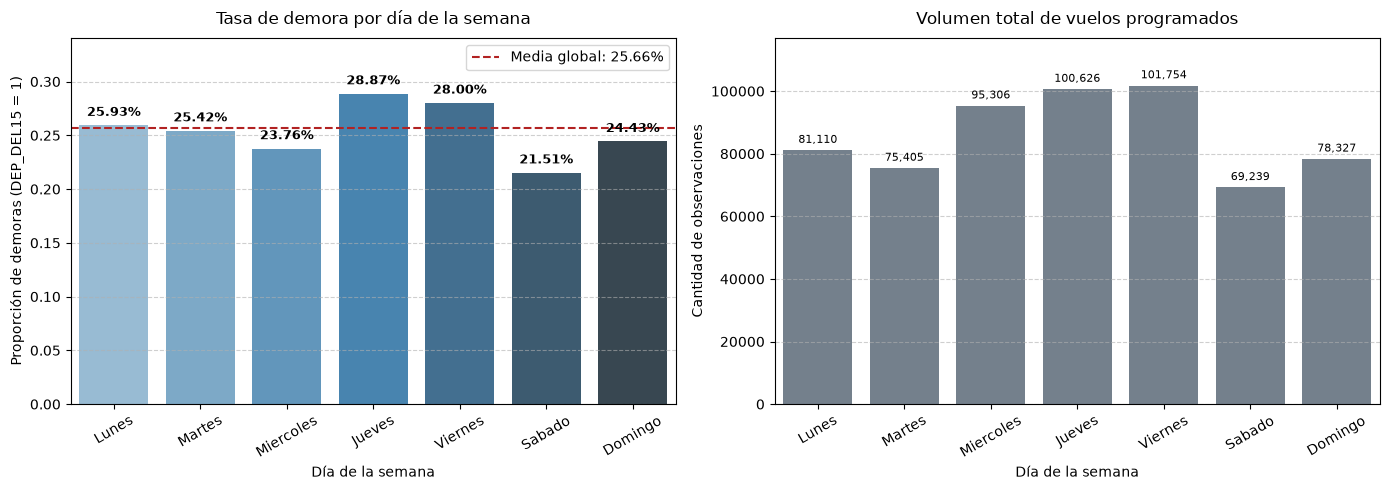

In [29]:
# VISUALIZACIÓN DEL VOLUMEN DE VUELOS Y TASA DE DEMORA POR DÍA DE LA SEMANA

# Orden cronológico estándar de la semana
orden_dias = ['Lunes', 'Martes', 'Miercoles', 'Jueves', 'Viernes', 'Sabado', 'Domingo']
data_plot = weekday_delays.reindex(orden_dias).reset_index()

# Configurar figura con dos paneles alineados
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


# Panel 1: Tasa de demora condicional (P(DEP_DEL15=1 | Día))

sns.barplot(
    data=data_plot, 
    x='DAY_OF_WEEK_NAME', 
    y='tasa_demora', 
    palette='Blues_d', 
    ax=ax1
)

# Línea de referencia del promedio global del mes 
media_global = df_processed['DEP_DEL15'].mean()
ax1.axhline(media_global, color='firebrick', linestyle='--', linewidth=1.5, label=f'Media global: {media_global:.2%}')

# Etiquetas con porcentaje exacto sobre cada barra
for i, val in enumerate(data_plot['tasa_demora']):
    ax1.text(i, val + 0.006, f'{val:.2%}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax1.set_title('Tasa de demora por día de la semana', fontsize=12, pad=10)
ax1.set_xlabel('Día de la semana', fontsize=10)
ax1.set_ylabel('Proporción de demoras (DEP_DEL15 = 1)', fontsize=10)
ax1.set_ylim(0, max(data_plot['tasa_demora']) * 1.18)
ax1.grid(axis='y', linestyle='--', alpha=0.6)
ax1.tick_params(axis='x', rotation=30)
ax1.legend(loc='upper right')

# Panel 2: Volumen total de vuelos programados (Soporte muestral)

sns.barplot(
    data=data_plot, 
    x='DAY_OF_WEEK_NAME', 
    y='total_vuelos', 
    color='slategray', 
    ax=ax2
)

# Etiquetas con cantidad de vuelos sobre cada barra
for i, val in enumerate(data_plot['total_vuelos']):
    ax2.text(i, val + 1500, f'{val:,}', ha='center', va='bottom', fontsize=8)

ax2.set_title('Volumen total de vuelos programados', fontsize=12, pad=10)
ax2.set_xlabel('Día de la semana', fontsize=10)
ax2.set_ylabel('Cantidad de observaciones', fontsize=10)
ax2.set_ylim(0, max(data_plot['total_vuelos']) * 1.15)
ax2.grid(axis='y', linestyle='--', alpha=0.6)
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Tabla de frecuencias absolutas y relativas sobre  DEP_DEL15
target_dist = pd.DataFrame({
    'Total_Vuelos': df_processed['DEP_DEL15'].value_counts(),
    'Proporcion': df_processed['DEP_DEL15'].value_counts(normalize=True)
})
print("--- DISTRIBUCIÓN DE DEP_DEL15 ---")
print(target_dist)

# 2. Métricas explícitas de desbalance y baseline (clasificador mayoritario)
n_total = len(df_processed)
n_neg, n_pos = target_dist.loc[0, 'Total_Vuelos'], target_dist.loc[1, 'Total_Vuelos']
p_pos = target_dist.loc[1, 'Proporcion']
imbalance_ratio = n_neg / n_pos #indica cuántas veces es más grande la clase mayoritaria frente a la minoritaria.

print(f"\nTotal observaciones válidas: {n_total:,}")
print(f"Prevalencia de clase positiva (Demora >= 15 min): {p_pos:.2%}")
print(f"Ratio de desbalance (Clase 0 / Clase 1): {imbalance_ratio:.2f}:1")
print(f"Línea de base trivial (Accuracy del Dummy Classifier mayoritario): {1 - p_pos:.2%}")

--- DISTRIBUCIÓN DE DEP_DEL15 ---
           Total_Vuelos  Proporcion
DEP_DEL15                          
0                447354    0.743401
1                154413    0.256599

Total observaciones válidas: 601,767
Prevalencia de clase positiva (Demora >= 15 min): 25.66%
Ratio de desbalance (Clase 0 / Clase 1): 2.90:1
Línea de base trivial (Accuracy del Dummy Classifier mayoritario): 74.34%


C:\Users\vagui\AppData\Local\Temp\ipykernel_10956\1038535321.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_dist.index, y=target_dist['Proporcion'], palette='Blues_d')


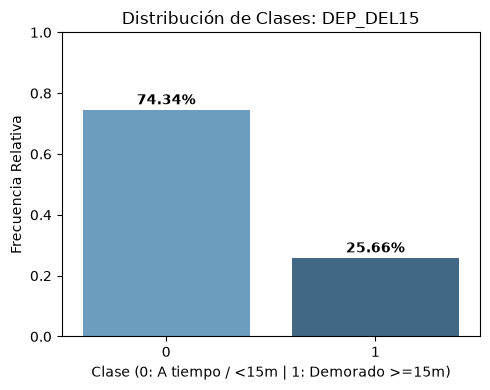

In [23]:
# 3. Histograma de frecuencias relativas
plt.figure(figsize=(5, 4))
sns.barplot(x=target_dist.index, y=target_dist['Proporcion'], palette='Blues_d')
plt.title('Distribución de Clases: DEP_DEL15')
plt.xlabel('Clase (0: A tiempo / <15m | 1: Demorado >=15m)')
plt.ylabel('Frecuencia Relativa')
plt.ylim(0, 1)
for i, val in enumerate(target_dist['Proporcion']):
    plt.text(i, val + 0.02, f'{val:.2%}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

--- RESUMEN ESTADÍSTICO DE VARIABLES CUANTITATIVAS SEGÚN DEP_DEL15 ---
                  Media (0: A tiempo)  Media (1: Demorado)  Mediana (0)  \
CRS_DEP_HOUR                    12.37                14.96         12.0   
CRS_ARR_HOUR                    14.05                16.32         14.0   
CRS_ELAPSED_TIME               145.08               147.47        127.0   
DISTANCE                       829.08               848.57        669.0   
DISTANCE_GROUP                   3.79                 3.87          3.0   

                  Mediana (1)  Desvío (0)  Desvío (1)  
CRS_DEP_HOUR             16.0        4.90        4.46  
CRS_ARR_HOUR             17.0        5.07        5.20  
CRS_ELAPSED_TIME        133.0       72.78       70.47  
DISTANCE                722.0      601.73      577.03  
DISTANCE_GROUP            3.0        2.36        2.27  

--- MATRIZ DE CORRELACIÓN CON DEP_DEL15 Y REDUNDANCIA ---
                  CRS_DEP_HOUR  CRS_ARR_HOUR  CRS_ELAPSED_TIME  DISTANCE  \
CRS_DEP

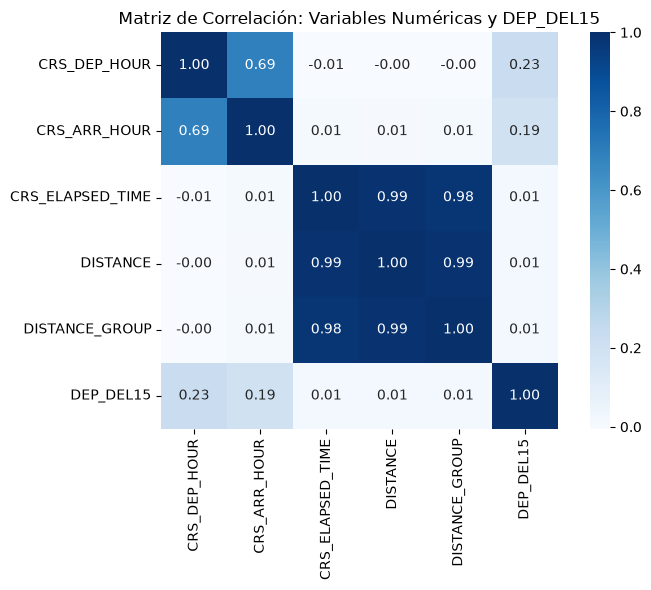

C:\Users\vagui\AppData\Local\Temp\ipykernel_10956\3008636981.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_processed, x='DEP_DEL15', y=col, ax=axes[i], palette='Set2')
C:\Users\vagui\AppData\Local\Temp\ipykernel_10956\3008636981.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_processed, x='DEP_DEL15', y=col, ax=axes[i], palette='Set2')
C:\Users\vagui\AppData\Local\Temp\ipykernel_10956\3008636981.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_processed, x='DEP_DEL15', y=col, ax=axes[i], palette='Set2'

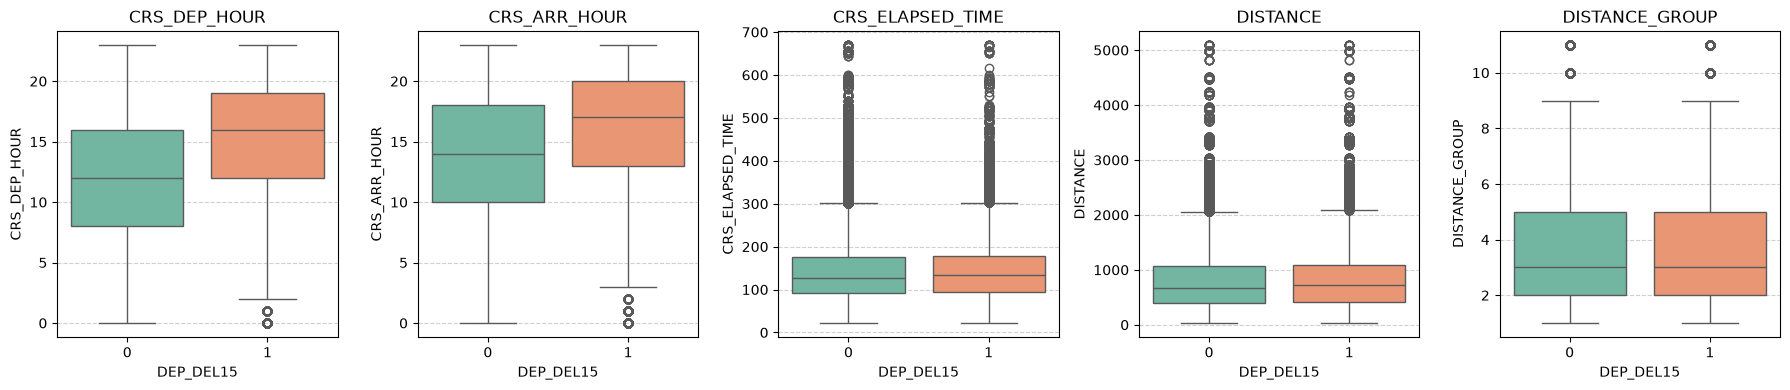

In [ ]:
# EXPLORACIÓN  DE VARIABLES CUANTITATIVA VS. TARGET

#-----------------------------------------------REVISAR ENFATICAMENTE------------------

# 1. Definir el espacio numérico depurado (excluye HHMM militar y variables de calendario)
num_features = [
    'CRS_DEP_HOUR', 
    'CRS_ARR_HOUR', 
    'CRS_ELAPSED_TIME', 
    'DISTANCE', 
    'DISTANCE_GROUP'
]

# 2. Tabla comparativa de posición y dispersión condicionada al target (0 vs 1)
stats_0 = df_processed[df_processed['DEP_DEL15'] == 0][num_features].agg(['mean', 'median', 'std']).T
stats_1 = df_processed[df_processed['DEP_DEL15'] == 1][num_features].agg(['mean', 'median', 'std']).T

summary_cuant = pd.DataFrame({
    'Media (0: A tiempo)': stats_0['mean'],
    'Media (1: Demorado)': stats_1['mean'],
    'Mediana (0)': stats_0['median'],
    'Mediana (1)': stats_1['median'],
    'Desvío (0)': stats_0['std'],
    'Desvío (1)': stats_1['std']
}).round(2)

print("--- RESUMEN ESTADÍSTICO DE VARIABLES CUANTITATIVAS SEGÚN DEP_DEL15 ---")
print(summary_cuant)

# 3. Matriz de correlación de Pearson completa (auditoría de colinealidad física y relación lineal)
print("\n--- MATRIZ DE CORRELACIÓN CON DEP_DEL15 Y REDUNDANCIA ---")
corr_matrix = df_processed[num_features + ['DEP_DEL15']].corr()
print(corr_matrix.round(3))

# Heatmap para evaluar correlación de forma directa
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', cbar=True, square=True)
plt.title('Matriz de Correlación: Variables Numéricas y DEP_DEL15')
plt.tight_layout()
plt.show()

# 4. Boxplots comparativos para evaluar dispersión, simetría y separación de clases
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(num_features):
    sns.boxplot(data=df_processed, x='DEP_DEL15', y=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('DEP_DEL15')
    axes[i].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()